# 01 · Análisis exploratorio
**Pregunta del proyecto:** entre las personas ocupadas de Puno, ¿quiénes tienen un **empleo informal**?

Fuente: Encuesta Permanente de Empleo Nacional (EPEN) 2025, INEI, departamento de Puno. Trabajamos solo con **personas ocupadas** (`OCUP300 = 1`). La variable objetivo es el indicador `Informal_P` del INEI (1 = informal, 2 = formal).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Datos: EPEN 2025 (INEI), departamento de Puno. El archivo está en data/ del repositorio.
NOMBRE = "21_Puno_EPEN_Anual_2025.csv"
RUTA = next((r for r in [f"../data/{NOMBRE}", f"data/{NOMBRE}", NOMBRE] if Path(r).exists()),
            "https://raw.githubusercontent.com/[USUARIO]/[REPOSITORIO]/main/data/" + NOMBRE)  # <- reemplazar

NUMERICAS = ["edad", "horas_semana", "ingreso_log", "n_limitaciones", "anios_estudio"]
CATEGORICAS = ["sexo", "area", "educacion", "lengua", "etnia", "ocupacion", "rama", "quiere_mas_horas"]

EDUC = {1: "Sin nivel/inicial", 2: "Sin nivel/inicial", 3: "Primaria incompleta", 4: "Primaria completa",
        5: "Secundaria incompleta", 6: "Secundaria completa", 7: "Sin nivel/inicial",
        8: "Superior no univ. incompleta", 9: "Superior no univ. completa",
        10: "Superior univ. incompleta", 11: "Superior univ. completa", 12: "Posgrado"}
ANIOS = {1: 0, 2: 0, 3: 3, 4: 6, 5: 8, 6: 11, 7: 0, 8: 12, 9: 14, 10: 13, 11: 16, 12: 18}  # años de estudio aprox.
OCUP = {0: "Fuerzas armadas", 1: "Directivos", 2: "Profesionales", 3: "Técnicos", 4: "Empleados de oficina",
        5: "Servicios y vendedores", 6: "Agricultores y pecuarios", 7: "Oficiales y artesanos",
        8: "Operadores de maquinaria", 9: "Ocupaciones elementales"}      # CIUO-08, gran grupo

def rama_ciiu(codigo):
    """Agrupa la división CIIU (4 dígitos, sin el cero inicial) en grandes ramas."""
    d = int(codigo) // 100
    if d <= 3:  return "Agricultura y pesca"
    if d <= 9:  return "Minería"
    if d <= 33: return "Manufactura"
    if d <= 39: return "Electricidad y agua"
    if d <= 43: return "Construcción"
    if d <= 47: return "Comercio"
    if d <= 53: return "Transporte"
    if d <= 56: return "Alojamiento y comidas"
    if d <= 82: return "Servicios a empresas"
    if d == 84: return "Administración pública"
    if d == 85: return "Educación"
    if d <= 88: return "Salud"
    return "Otros servicios y hogares"

def cargar_datos():
    raw = pd.read_csv(RUTA)
    # Población de estudio: personas OCUPADAS (OCUP300 = 1) con el indicador de informalidad del INEI
    d = raw[(raw["OCUP300"] == 1) & raw["Informal_P"].notna()].copy()
    out = pd.DataFrame({
        "edad": d["C208"], "horas_semana": d["whoraT"], "ingreso_log": np.log1p(d["INGTOTP"]),
        "n_limitaciones": (d[[f"C375_{i}" for i in range(1, 7)]] == 1).sum(axis=1),
        "anios_estudio": d["C366"].map(ANIOS),
        "sexo": d["C207"].map({1: "Hombre", 2: "Mujer"}),
        "area": d["AREA"].map({1: "Urbano", 2: "Rural"}),
        "educacion": d["C366"].map(EDUC),
        "lengua": d["C376"].map({1: "Quechua", 2: "Aimara", 10: "Castellano"}).fillna("Otra"),
        "etnia": d["C377"].map({1: "Quechua", 2: "Aimara", 6: "Blanco", 7: "Mestizo"}).fillna("Otra/No sabe"),
        "ocupacion": (d["C308_COD"] // 1000).map(OCUP),
        "rama": d["C309_COD"].map(rama_ciiu),
        "quiere_mas_horas": d["C333"].map({1: "Sí", 2: "No"}).fillna("No"),
        "informal": (d["Informal_P"] == 1).astype(int),     # 1 = empleo informal, 2 = formal (ver data/README.md)
        "grupo": d["LLAVE_PANEL"].astype(str),               # identifica a la persona (el panel la repite)
        "ingreso": d["INGTOTP"]})
    return out.reset_index(drop=True)

df = cargar_datos()
X, y, grupos = df[NUMERICAS + CATEGORICAS], df["informal"], df["grupo"]
print(df.shape, f"| empleo informal: {y.mean():.1%} | personas distintas: {grupos.nunique()}")

(7836, 16) | empleo informal: 77.8% | personas distintas: 5479


## ¿Cuántos tienen empleo informal?

informal
informal    6100
formal      1736
Name: count, dtype: int64


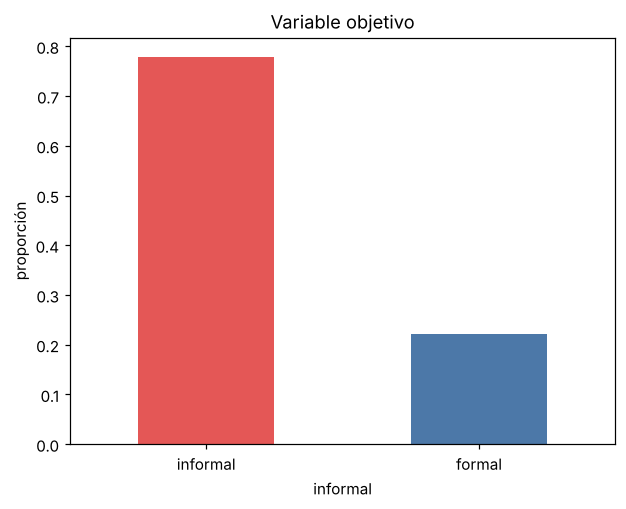

In [2]:
etiquetas = {0: "formal", 1: "informal"}
print(y.value_counts().rename(etiquetas))
y.value_counts(normalize=True).rename(etiquetas).plot.bar(color=["#E45756", "#4C78A8"])
plt.ylabel("proporción"); plt.title("Variable objetivo"); plt.xticks(rotation=0); plt.show()

## Las filas no son independientes
La EPEN es un **panel**: una misma persona puede aparecer en dos meses distintos del año. Si una persona queda en entrenamiento y la misma persona en test, el modelo "reconoce" a la persona y las métricas salen infladas.

In [3]:
por_persona = grupos.value_counts()
print(f"filas: {len(df)} · personas distintas: {grupos.nunique()} · personas con 2 observaciones: {(por_persona == 2).sum()}")
print("→ Toda la validación se hace por persona (StratifiedGroupKFold con LLAVE_PANEL).")

filas: 7836 · personas distintas: 5479 · personas con 2 observaciones: 2357
→ Toda la validación se hace por persona (StratifiedGroupKFold con LLAVE_PANEL).


## Hallazgo 1 · El nivel educativo

                             % informal     n
educacion                                    
Sin nivel/inicial                    99   245
Primaria incompleta                  98   646
Primaria completa                    97   671
Secundaria incompleta                98   712
Secundaria completa                  93  2080
Superior no univ. incompleta         86   396
Superior univ. incompleta            74   508
Superior no univ. completa           64   816
Superior univ. completa              50  1158
Posgrado                             20   604


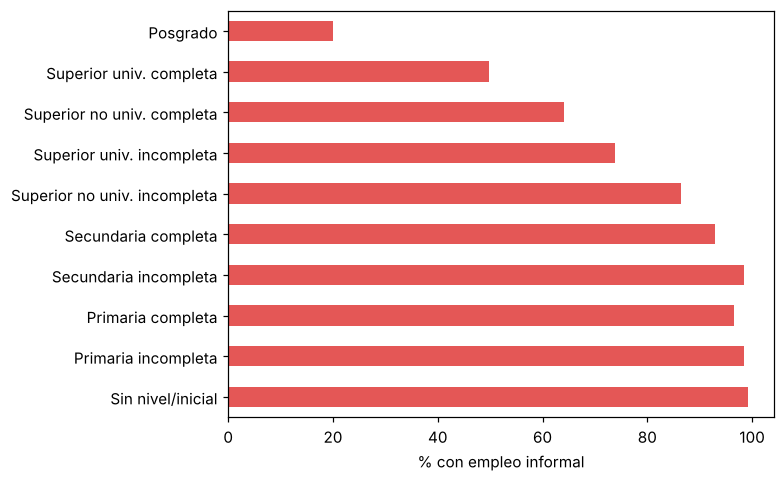

In [4]:
t = df.groupby("educacion").agg(informal=("informal", "mean"), n=("informal", "size"), anios=("anios_estudio", "first")).sort_values("anios")
print((t["informal"] * 100).round(0).astype(int).astype(str).rename("% informal").to_frame().join(t["n"]))
(t["informal"] * 100).plot.barh(color="#E45756"); plt.xlabel("% con empleo informal"); plt.ylabel(""); plt.show()

## Hallazgo 2 · Zona, sexo y lengua materna

In [5]:
for col in ["area", "sexo", "lengua"]:
    t = df[df[col] != "Otra"].groupby(col)["informal"].agg(["mean", "size"])
    print(col.upper()); print((t["mean"] * 100).round(0).astype(int).astype(str).add(" %").to_frame("% informal").join(t["size"].rename("n")), "\n")

AREA
       % informal     n
area                   
Rural        98 %  1289
Urbano       74 %  6547 

SEXO
       % informal     n
sexo                   
Hombre       75 %  3780
Mujer        80 %  4056 

LENGUA
           % informal     n
lengua                     
Aimara           84 %  1633
Castellano       68 %  3368
Quechua          86 %  2830 



## Hallazgo 3 · La edad

edad
14–24       95 %
25–34       78 %
35–44       73 %
45–54       71 %
55–64       72 %
65 o más    88 %
Name: informal, dtype: str


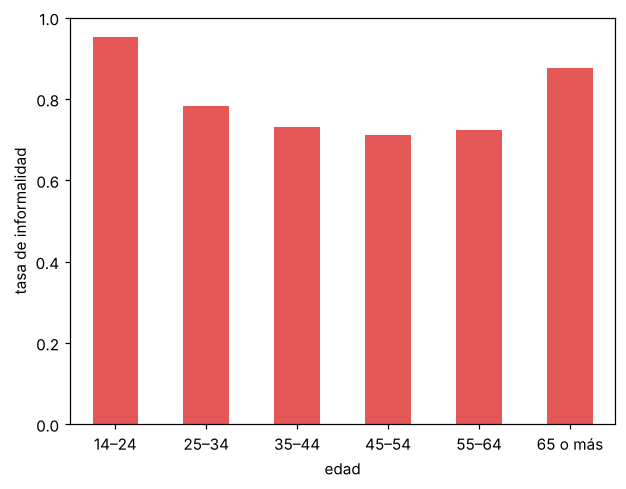

In [6]:
tramos = pd.cut(df["edad"], [13, 24, 34, 44, 54, 64, 120], labels=["14–24", "25–34", "35–44", "45–54", "55–64", "65 o más"])
tasa = df.groupby(tramos, observed=True)["informal"].mean()
print((tasa * 100).round(0).astype(int).astype(str) + " %")
tasa.plot.bar(color="#E45756"); plt.ylabel("tasa de informalidad"); plt.xlabel("edad"); plt.xticks(rotation=0); plt.show()

## Hallazgo 4 · La ocupación y la rama de actividad

In [7]:
for col in ["ocupacion", "rama"]:
    t = df.groupby(col)["informal"].agg(["mean", "size"]).sort_values("mean")
    print(col.upper()); print((t["mean"] * 100).round(0).astype(int).astype(str).add(" %").to_frame("% informal").join(t["size"].rename("n")), "\n")

OCUPACION
                         % informal     n
ocupacion                                
Fuerzas armadas                 0 %    41
Directivos                     15 %    40
Profesionales                  19 %   995
Empleados de oficina           42 %   226
Técnicos                       47 %   496
Servicios y vendedores         84 %  1356
Oficiales y artesanos          90 %   843
Operadores de maquinaria       94 %   516
Ocupaciones elementales        95 %  2399
Agricultores y pecuarios      100 %   924 

RAMA
                          % informal     n
rama                                      
Educación                       13 %   666
Administración pública          27 %   428
Salud                           31 %   237
Servicios a empresas            49 %   351
Electricidad y agua             58 %    36
Minería                         65 %    93
Otros servicios y hogares       87 %   314
Comercio                        87 %  1756
Manufactura                     90 %   630
Constr

## Hallazgo 5 · El ingreso

Ingreso mensual de la ocupación principal (S/):
          median    mean
formal    2700.0  2770.0
informal   450.0   751.0


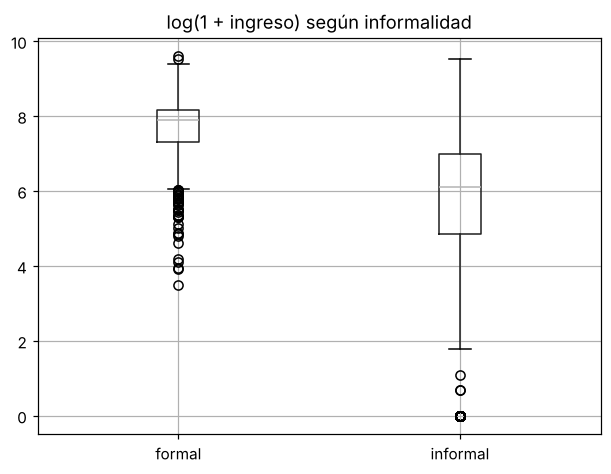

In [8]:
r = df.groupby("informal")["ingreso"].agg(["median", "mean"]).round(0)
r.index = ["formal", "informal"]
print("Ingreso mensual de la ocupación principal (S/):"); print(r)
df.boxplot(column="ingreso_log", by="informal"); plt.suptitle(""); plt.title("log(1 + ingreso) según informalidad")
plt.xticks([1, 2], ["formal", "informal"]); plt.xlabel(""); plt.show()

## Variables que NO usamos: fuga de datos
El INEI construye `Informal_P` a partir de preguntas sobre el **registro de la empresa en SUNAT** (`C312`), los **libros contables** (`C313`), el **tipo de trabajador** (`C310`), el **tamaño de la empresa** (`C317`) y el **seguro de salud y pensiones** (`SEGURO1`, `C361`–`C365`). Si las usáramos, el modelo solo "descubriría" la regla de cálculo. Lo comprobamos con la más obvia:

In [9]:
raw = pd.read_csv(RUTA)
oc = raw[(raw["OCUP300"] == 1) & raw["Informal_P"].notna()]
reg = oc["C312"].map({1: "Persona jurídica", 2: "Persona natural con RUC", 3: "NO registrado en SUNAT"}).fillna("No aplica")
print(((oc["Informal_P"] == 1).groupby(reg).mean() * 100).round(0).astype(int).astype(str).add(" %").rename("% informal"))

C312
NO registrado en SUNAT     100 %
No aplica                   18 %
Persona jurídica            35 %
Persona natural con RUC     49 %
Name: % informal, dtype: str


**Todos** los trabajadores cuya empresa no está registrada en SUNAT son informales por construcción. Por eso excluimos `C310`, `C311`, `C312`, `C313`, `C317`, `C317A`, `C338`, `SEGURO1`, `C361`–`C365` y las variables de ingresos por tipo de trabajador (usamos solo el ingreso mensual total de la ocupación principal).

## Hallazgos principales
1. **Casi 8 de cada 10 ocupados (78 %) tienen empleo informal.** Las clases están desbalanceadas, así que no usaremos la accuracy.
2. **La educación es la señal más fuerte:** de 99 % de informalidad sin nivel a **20 %** con posgrado. Con secundaria completa o menos, casi todos son informales (93 % o más).
3. **La zona pesa mucho:** **98 %** en el área rural contra **74 %** en la urbana. Con lengua materna quechua o aimara, 86 % y 84 %, contra 68 % en castellano.
4. **La edad forma una "U":** 95 % entre los 14 y 24 años, 71 % entre los 45 y 54, y 88 % a partir de los 65.
5. **La ocupación y la rama importan:** la agricultura es 100 % informal; los profesionales, 19 %; el sector educación, 13 %.
6. **El ingreso separa a los dos grupos:** la mediana es de S/ 2 700 en el empleo formal y de S/ 450 en el informal.
7. **El panel exige validar por persona:** 2 357 personas aparecen dos veces.